# RD-robustness (#4) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).

## Question

**Is the reaction-diffusion (RD) spatial structure found by the 2026-04-27 *spatial* objective
robust under pure-evolutionary optimization?** I.e. when the balanced-composite spatial winners
are run long under pure evolution, does their RD-scale structure *persist* (final ≈ mean) or
*decay* (final ≪ mean)?

## Method

`rd_under_pure_evo`: take the 10 distinct 2026-04-27 evo+spatial winner recipes, run each 12k
ticks × 3 seeds = 30 runs under pure evolution. Diagnostic:
`correlation_length_final_over_mean` (persistence ratio) and `dyn_excess_pc` vs spatial
degeneracy (`largest_patch_final_over_mean`).

## Headline result

**No — RD structure is not robust.** `correlation_length` final/mean median = **0.23** (all 30
runs decay) → the RD structure was an artifact of the 2026-04-27 *spatial* objective, not a
pure-evo attractor. Two regimes: **8/10** keep dynamic turnover (`dyn_excess` 12–27) while
spatial correlation washes out; **2/10** collapse to a **static colony-filling blob**
(`largest_patch` f/m ≈ 1.0, ~70% of grid frozen) and have the **lowest** `dyn_excess` (~5.8) —
exactly the "suspect the metric" degenerate cases NP predicted.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_restructure


In [2]:
rd = pd.read_csv(ROOT / "Research/Reaction-diffusion/Scans/2026-05-18_rd_under_pure_evo/results.csv")
print(f"{len(rd)} runs, extinct={int(rd.extinct.sum())}")
print("correlation_length final/mean  median = %.3f  (persist would be ~1)"
      % rd.correlation_length_final_over_mean.median())


30 runs, extinct=0
correlation_length final/mean  median = 0.230  (persist would be ~1)


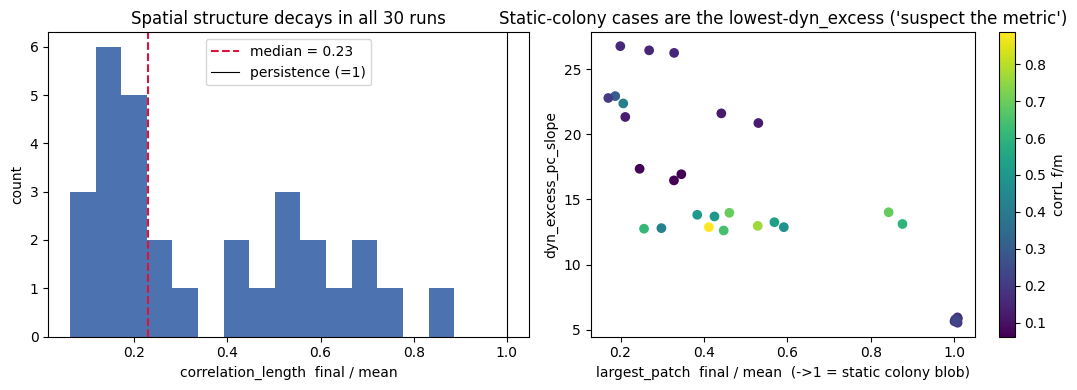

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) persistence ratio distribution
axes[0].hist(rd.correlation_length_final_over_mean, bins=15, color="#4C72B0")
axes[0].axvline(rd.correlation_length_final_over_mean.median(), color="crimson", ls="--",
                label=f"median = {rd.correlation_length_final_over_mean.median():.2f}")
axes[0].axvline(1.0, color="k", lw=0.8, label="persistence (=1)")
axes[0].set_xlabel("correlation_length  final / mean")
axes[0].set_ylabel("count"); axes[0].set_title("Spatial structure decays in all 30 runs")
axes[0].legend()

# (b) static-blob collapse == lowest dyn_excess
sc = axes[1].scatter(rd.largest_patch_final_over_mean, rd.dyn_excess_pc_slope,
                     c=rd.correlation_length_final_over_mean, cmap="viridis")
axes[1].set_xlabel("largest_patch  final / mean  (->1 = static colony blob)")
axes[1].set_ylabel("dyn_excess_pc_slope")
axes[1].set_title("Static-colony cases are the lowest-dyn_excess ('suspect the metric')")
fig.colorbar(sc, ax=axes[1], label="corrL f/m")
fig.tight_layout(); plt.show()


*Sources:* `Research/Reaction-diffusion/Scans/2026-05-18_rd_under_pure_evo/`, `Research/Activity-metrics/Scans/2026-05-17_pure_evo_analysis.md`,
`Docs/devlog/2026-05-17_research-campaigns.md`.